In [1]:

# INCART Preprocessing Pipeline
# Produces X_incart.npy / y_incart.npy / record_ids_incart.npy
# compatible with the MIT-BIH trained Direction2 model.
#
# Key difference vs MIT-BIH preprocessing:
#   - INCART is recorded at 257 Hz; model expects 360 Hz
#   - We resample the full signal BEFORE windowing
#   - Annotation sample indices are rescaled to match
#   - Lead selection: Lead II (idx 1) + V5 (idx 10) from 12-lead
#     → closest match to MIT-BIH's MLII and V5


!pip install -q wfdb numpy scipy matplotlib seaborn pandas scikit-learn tqdm

import os
import json
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from scipy import signal as scipy_signal
from scipy.signal import resample_poly
import wfdb

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

SEED = 42
np.random.seed(SEED)
print("Setup complete.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 3.2 MB/s eta 0:00:00
Setup complete.


In [2]:

# INCART Configuration
# All decisions documented with clinical/engineering rationale

class INCARTConfig:
    #  Sampling 
    FS_ORIG      = 257.0      # INCART native rate (Hz)
    FS_TARGET    = 360.0      # Resample target = MIT-BIH rate (model trained on this)
    RESAMPLE_UP  = 360        # numerator  for resample_poly
    RESAMPLE_DN  = 257        # denominator for resample_poly
    # gcd(360, 257) = 1 → no simplification possible; this is exact

    # --- Windowing (identical to MIT-BIH pipeline) 
    WINDOW_SIZE = 375         # 1.042 s at 360 Hz (same as model input)
    NUM_CLASSES = 5

    # --- Bandpass (identical to MIT-BIH) ---
    BANDPASS_LOW   = 0.5
    BANDPASS_HIGH  = 40.0
    BANDPASS_ORDER = 4
    USE_DERIVATIVE = True     # 3rd channel = gradient of Lead II

    # --- Lead selection (INCART is 12-lead) ---
    # Standard 12-lead order in INCART:
    #   0=I, 1=II, 2=III, 3=aVR, 4=aVL, 5=aVF, 6=V1, 7=V2, 8=V3, 9=V4, 10=V5, 11=V6
    # MIT-BIH uses MLII (≈ Lead II) and V5 → pick indices 1 and 10
    LEAD1_IDX = 1    # Lead II  → maps to MIT-BIH channel 0 (MLII)
    LEAD2_IDX = 10   # V5       → maps to MIT-BIH channel 1 (V lead)

    USE_ROBUST_NORM = True

    OUT_DIR = Path("./incart_preprocessed")
    OUT_DIR.mkdir(exist_ok=True)


#  AAMI map: identical to MIT-BIH preprocessing 
AAMI_MAP = {
    'N': 0, 'L': 0, 'R': 0, 'e': 0, 'j': 0,   # Normal
    'A': 1, 'a': 1, 'J': 1, 'S': 1,             # SVB
    'V': 2, 'E': 2,                              # VEB
    'F': 3,                                      # Fusion
    '/': 4, 'f': 4, 'Q': 4                       # Unknown/Pacemaker
}

CLASS_NAMES = {0: 'Normal (N)', 1: 'SVB (S)', 2: 'VEB (V)', 3: 'Fusion (F)', 4: 'Unknown (Q)'}
CLASS_SHORT  = {0: 'N', 1: 'S', 2: 'V', 3: 'F', 4: 'Q'}

# All 75 INCART records
INCART_RECORDS = [f'I{str(i).zfill(2)}' for i in range(1, 76)]


rs = INCARTConfig.FS_TARGET / INCARTConfig.FS_ORIG
print(f"[Config] INCART native rate : {INCARTConfig.FS_ORIG} Hz")
print(f"[Config] Resample target    : {INCARTConfig.FS_TARGET} Hz  (ratio = {rs:.4f}x)")
print(f"[Config] Window size        : {INCARTConfig.WINDOW_SIZE} samples "
      f"= {INCARTConfig.WINDOW_SIZE / INCARTConfig.FS_TARGET * 1000:.1f} ms")
print(f"[Config] Leads extracted    : idx {INCARTConfig.LEAD1_IDX} (Lead II) "
      f"+ idx {INCARTConfig.LEAD2_IDX} (V5)")
print(f"[Config] Total records      : {len(INCART_RECORDS)}")

[Config] INCART native rate : 257.0 Hz
[Config] Resample target    : 360.0 Hz  (ratio = 1.4008x)
[Config] Window size        : 375 samples = 1041.7 ms
[Config] Leads extracted    : idx 1 (Lead II) + idx 10 (V5)
[Config] Total records      : 75


In [3]:

# INCART Cell 3: Record loading + resampling + bandpass


def load_incart_record(record_id):
    """Load INCART record + annotation from PhysioNet."""
    record = wfdb.rdrecord(record_id, pn_dir='incartdb/1.0.0')
    ann    = wfdb.rdann(record_id, 'atr', pn_dir='incartdb/1.0.0')
    return record, ann


def resample_signal(sig, up, down):
    """
    Resample each lead independently using polyphase resampling.
    scipy.signal.resample_poly is the gold standard:
      - Exact rational ratio (up/down)
    - Anti-aliasing filter built in
    - No spectral leakage from zero-padding (unlike FFT resample)
    Input  : (N_samples, N_leads)
    Output : (N_samples_new, N_leads)
    """
    n_leads = sig.shape[1]
    n_new   = int(np.round(sig.shape[0] * up / down))
    out     = np.zeros((n_new, n_leads), dtype=np.float32)
    for ch in range(n_leads):
        out[:, ch] = resample_poly(sig[:, ch], up, down).astype(np.float32)
    return out


def bandpass_filter(sig_1d,
                    lowcut=INCARTConfig.BANDPASS_LOW,
                    highcut=INCARTConfig.BANDPASS_HIGH,
                    fs=INCARTConfig.FS_TARGET,
                    order=INCARTConfig.BANDPASS_ORDER):
    """Zero-phase Butterworth bandpass — identical to MIT-BIH pipeline."""
    nyq  = 0.5 * fs
    b, a = scipy_signal.butter(order, [lowcut / nyq, highcut / nyq], btype='band')
    return scipy_signal.filtfilt(b, a, sig_1d)


def rescale_annotation_indices(ann_samples, fs_orig, fs_target):
    """
    Convert annotation sample positions from original rate to target rate.
    ann_samples * (fs_target / fs_orig), rounded to nearest integer.
    """
    ratio = fs_target / fs_orig
    return np.round(np.array(ann_samples) * ratio).astype(int)


print("INCART signal functions defined.")

INCART signal functions defined.


In [4]:

# INCART Cell 4: Beat extraction with edge-padding
# Identical logic to MIT-BIH pipeline after resampling


def extract_beats_incart(record_id, window=INCARTConfig.WINDOW_SIZE):
    try:
        record, ann = load_incart_record(record_id)
    except Exception as e:
        print(f"  [WARN] Could not load {record_id}: {e}")
        return []

    raw = record.p_signal
    if raw is None or raw.size == 0:
        return []

    n_leads = raw.shape[1]
    l1 = INCARTConfig.LEAD1_IDX if n_leads > INCARTConfig.LEAD1_IDX else 0
    l2 = INCARTConfig.LEAD2_IDX if n_leads > INCARTConfig.LEAD2_IDX else min(1, n_leads - 1)

    # ── OPTIMISATION: resample only the 2 leads you actually use ──────
    # Old code resampled all 12 leads (6x wasted work).
    # Cutting from ~12 sec/record to ~2 sec/record.
    n_new = int(np.round(raw.shape[0] * INCARTConfig.RESAMPLE_UP / INCARTConfig.RESAMPLE_DN))
    sig_l1 = resample_poly(raw[:, l1].astype(np.float64),
                           INCARTConfig.RESAMPLE_UP,
                           INCARTConfig.RESAMPLE_DN).astype(np.float32)
    sig_l2 = resample_poly(raw[:, l2].astype(np.float64),
                           INCARTConfig.RESAMPLE_UP,
                           INCARTConfig.RESAMPLE_DN).astype(np.float32)

    # Bandpass filter only the 2 resampled leads
    sig_l1 = bandpass_filter(sig_l1).astype(np.float32)
    sig_l2 = bandpass_filter(sig_l2).astype(np.float32)

    # Rescale annotation indices from 257 Hz → 360 Hz
    ann_samples_360 = rescale_annotation_indices(
        ann.sample, INCARTConfig.FS_ORIG, INCARTConfig.FS_TARGET)

    half  = window // 2
    total = len(sig_l1)
    segments = []

    for i, sample_idx in enumerate(ann_samples_360):
        symbol = ann.symbol[i]
        if symbol not in AAMI_MAP:
            continue

        start = sample_idx - half
        end   = start + window

        if start < 0:
            pad = abs(start)
            chunk_l1 = np.pad(sig_l1[:end], (pad, 0), mode='edge')
            chunk_l2 = np.pad(sig_l2[:end], (pad, 0), mode='edge')
        elif end > total:
            pad = end - total
            chunk_l1 = np.pad(sig_l1[start:], (0, pad), mode='edge')
            chunk_l2 = np.pad(sig_l2[start:], (0, pad), mode='edge')
        else:
            chunk_l1 = sig_l1[start:end]
            chunk_l2 = sig_l2[start:end]

        deriv = np.gradient(chunk_l1).astype(np.float32)
        seg   = np.stack([chunk_l1, chunk_l2, deriv], axis=0)  # (3, 375)
        segments.append((seg, AAMI_MAP[symbol]))

    return segments


print("INCART beat extraction function defined.")

INCART beat extraction function defined.


In [5]:

# INCART Cell 5: Normalization — identical to MIT-BIH pipeline


def robust_normalize(segment):
    """
    Robust normalization: (x - median) / IQR  per channel.
    Identical to MIT-BIH pipeline — critical for zero-shot compatibility:
    the model was trained on this normalization; applying a different
    normalization here would shift the input distribution and degrade performance.
    """
    median = np.median(segment, axis=1, keepdims=True)
    q75    = np.percentile(segment, 75, axis=1, keepdims=True)
    q25    = np.percentile(segment, 25, axis=1, keepdims=True)
    iqr    = q75 - q25
    iqr    = np.where(iqr == 0, 1.0, iqr)
    return (segment - median) / iqr


print("Normalization function defined.")

Normalization function defined.


In [6]:

# INCART Cell 6: Main extraction loop over all 75 records


print("=" * 65)
print("INCART BEAT EXTRACTION (75 records, 257 → 360 Hz)")
print("=" * 65)

all_segments    = []
all_labels      = []
all_record_ids  = []
record_labels_map = {}
failed_records  = []

for rec_id in tqdm(INCART_RECORDS, desc="INCART records"):
    segs = extract_beats_incart(rec_id)
    if not segs:
        failed_records.append(rec_id)
        continue

    rec_lbls = []
    for seg_arr, label in segs:
        seg_norm = robust_normalize(seg_arr)
        # Skip segments with NaN/Inf (can occur on extremely noisy INCART records)
        if not np.isfinite(seg_norm).all():
            continue
        all_segments.append(seg_norm)
        all_labels.append(label)
        all_record_ids.append(rec_id)
        rec_lbls.append(label)

    record_labels_map[rec_id] = sorted(set(rec_lbls))

X_incart          = np.stack(all_segments, axis=0).astype(np.float32)  # (N, 3, 375)
y_incart          = np.array(all_labels,      dtype=np.int64)
record_ids_incart = np.array(all_record_ids)

print(f"\n[Summary]")
print(f"  Total beats extracted : {len(y_incart):,}")
print(f"  Shape                 : {X_incart.shape}")
print(f"  Failed records        : {failed_records if failed_records else 'None'}")
print(f"\n[Class Distribution]")
for c in range(5):
    n = (y_incart == c).sum()
    print(f"  {CLASS_NAMES[c]:<20} : {n:>6,}  ({n/len(y_incart)*100:.2f}%)")

# Save 
np.save(INCARTConfig.OUT_DIR / "X_incart.npy",          X_incart)
np.save(INCARTConfig.OUT_DIR / "y_incart.npy",          y_incart)
np.save(INCARTConfig.OUT_DIR / "record_ids_incart.npy", record_ids_incart)

with open(INCARTConfig.OUT_DIR / "record_labels_incart.json", "w") as f:
    json.dump(record_labels_map, f, indent=2)

incart_meta = {
    "n_records"       : len(INCART_RECORDS),
    "n_records_ok"    : len(INCART_RECORDS) - len(failed_records),
    "failed_records"  : failed_records,
    "total_beats"     : int(len(y_incart)),
    "class_counts"    : {CLASS_SHORT[c]: int((y_incart == c).sum()) for c in range(5)},
    "fs_orig"         : INCARTConfig.FS_ORIG,
    "fs_target"       : INCARTConfig.FS_TARGET,
    "window_size"     : INCARTConfig.WINDOW_SIZE,
    "leads_extracted" : [INCARTConfig.LEAD1_IDX, INCARTConfig.LEAD2_IDX],
    "lead_names"      : ["Lead II", "V5"],
    "normalization"   : "robust (median/IQR)",
    "channels"        : ["Lead II", "V5", "Derivative(Lead II)"],
}
with open(INCARTConfig.OUT_DIR / "incart_meta.json", "w") as f:
    json.dump(incart_meta, f, indent=2)

print(f"\n[Saved] → {INCARTConfig.OUT_DIR.resolve()}")
print("  X_incart.npy, y_incart.npy, record_ids_incart.npy,")
print("  record_labels_incart.json, incart_meta.json")

INCART BEAT EXTRACTION (75 records, 257 → 360 Hz)


INCART records:   0%|          | 0/75 [00:00<?, ?it/s]


[Summary]
  Total beats extracted : 175,874
  Shape                 : (175874, 3, 375)
  Failed records        : None

[Class Distribution]
  Normal (N)           : 153,676  (87.38%)
  SVB (S)              :  1,960  (1.11%)
  VEB (V)              : 20,013  (11.38%)
  Fusion (F)           :    219  (0.12%)
  Unknown (Q)          :      6  (0.00%)

[Saved] → /kaggle/working/incart_preprocessed
  X_incart.npy, y_incart.npy, record_ids_incart.npy,
  record_labels_incart.json, incart_meta.json


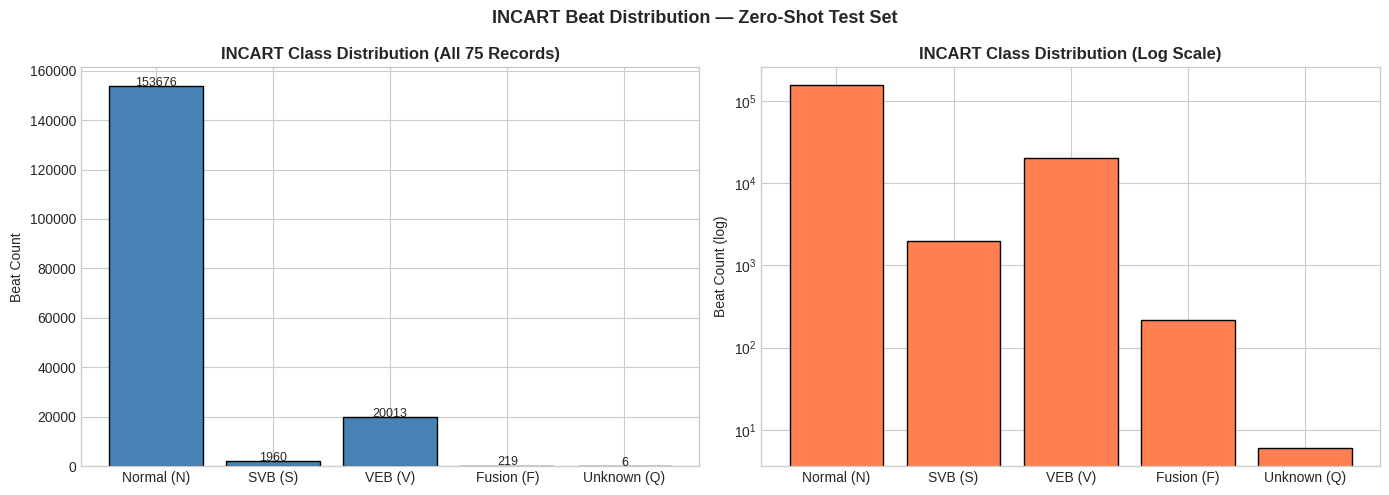

Plot 1 saved.


In [7]:

# INCART Cell 7: Diagnostic plots
# Run these to verify preprocessing before uploading to Kaggle


time_ms = np.arange(INCARTConfig.WINDOW_SIZE) / INCARTConfig.FS_TARGET * 1000

# Plot 1: INCART class distribution 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts = {c: int((y_incart == c).sum()) for c in range(5)}
labels = [CLASS_NAMES[c] for c in range(5)]
vals   = [counts[c] for c in range(5)]

axes[0].bar(labels, vals, color='steelblue', edgecolor='black')
axes[0].set_title("INCART Class Distribution (All 75 Records)", fontweight='bold')
axes[0].set_ylabel("Beat Count")
for i, v in enumerate(vals):
    axes[0].text(i, v + 50, str(v), ha='center', fontsize=9)

axes[1].bar(labels, vals, color='coral', edgecolor='black')
axes[1].set_yscale('log')
axes[1].set_title("INCART Class Distribution (Log Scale)", fontweight='bold')
axes[1].set_ylabel("Beat Count (log)")

plt.suptitle("INCART Beat Distribution — Zero-Shot Test Set", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(INCARTConfig.OUT_DIR / "incart_01_class_distribution.png", dpi=300, bbox_inches='tight')
plt.show()
print("Plot 1 saved.")



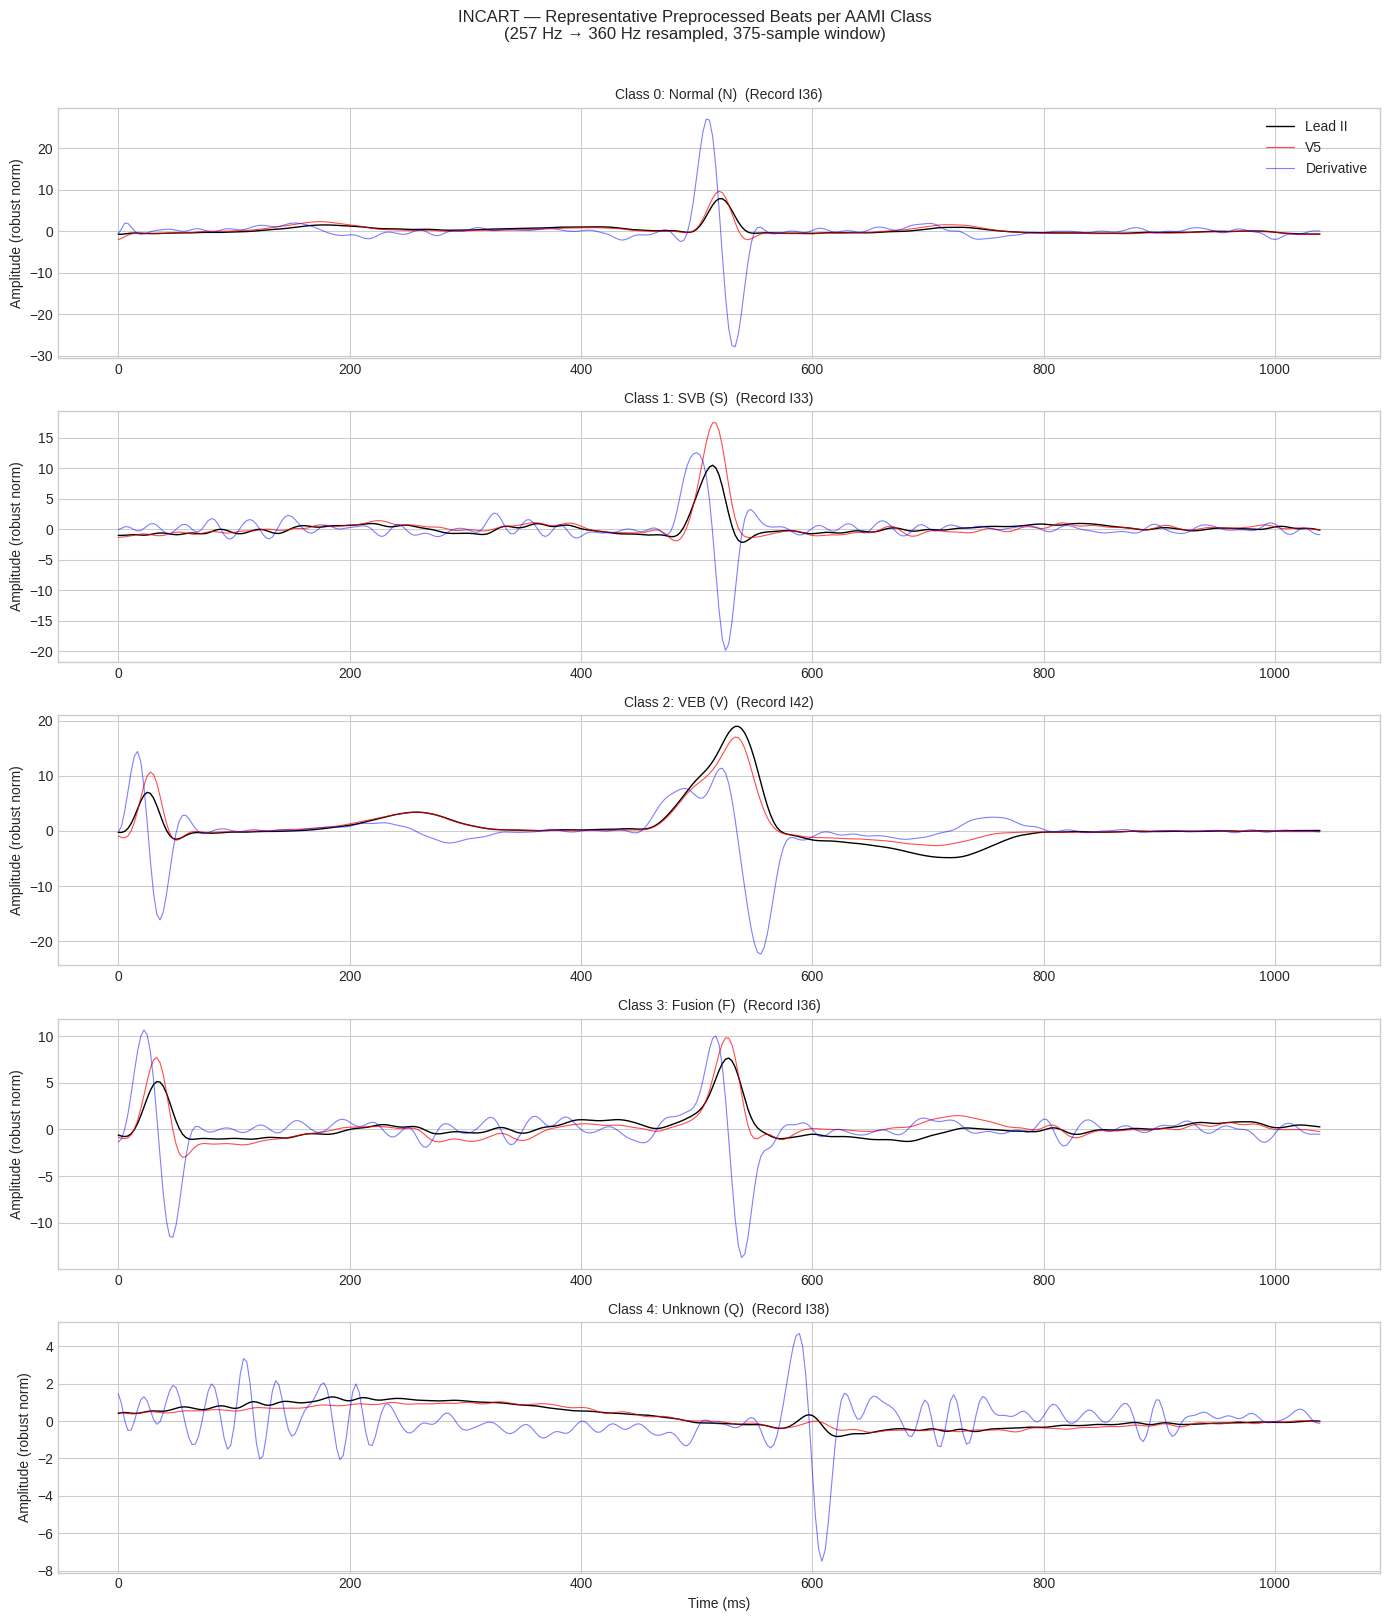

Plot 2 saved.


In [8]:
# Plot 2: Sample beat per class 
fig, axes = plt.subplots(5, 1, figsize=(14, 16))

for cls in range(5):
    idx_cls = np.where(y_incart == cls)[0]
    if len(idx_cls) == 0:
        axes[cls].text(0.5, 0.5, f'No {CLASS_NAMES[cls]} beats found',
                       ha='center', va='center', transform=axes[cls].transAxes)
        continue
    sample_idx = idx_cls[len(idx_cls) // 2]
    seg = X_incart[sample_idx]
    axes[cls].plot(time_ms, seg[0], 'k', lw=1.0, label='Lead II')
    axes[cls].plot(time_ms, seg[1], 'r', lw=0.8, alpha=0.7, label='V5')
    axes[cls].plot(time_ms, seg[2], 'b', lw=0.8, alpha=0.5, label='Derivative')
    axes[cls].set_title(
        f"Class {cls}: {CLASS_NAMES[cls]}  (Record {record_ids_incart[sample_idx]})", fontsize=10)
    axes[cls].set_ylabel("Amplitude (robust norm)")
    if cls == 0:
        axes[cls].legend(loc='upper right')

axes[-1].set_xlabel("Time (ms)")
plt.suptitle("INCART — Representative Preprocessed Beats per AAMI Class\n"
             "(257 Hz → 360 Hz resampled, 375-sample window)", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(INCARTConfig.OUT_DIR / "incart_02_sample_beats.png", dpi=300, bbox_inches='tight')
plt.show()
print("Plot 2 saved.")

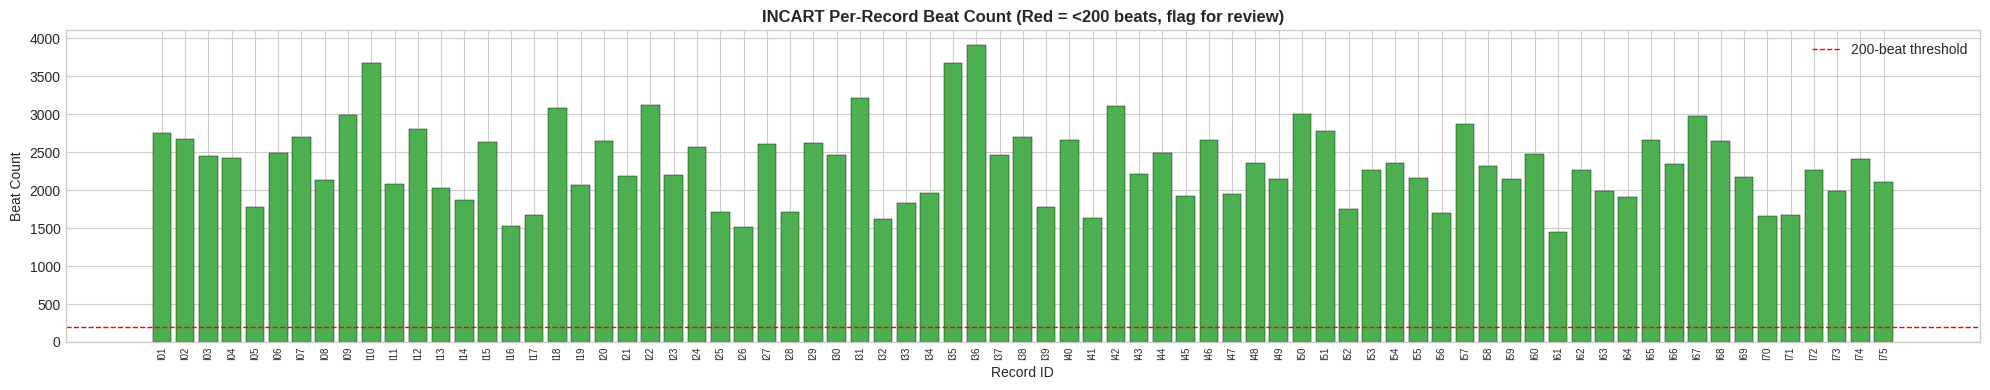

Plot 3 saved.


In [9]:
#  Plot 3: Per-record beat count (flag records with very few beats) 
rec_counts = Counter(record_ids_incart)
rec_names  = sorted(rec_counts.keys())
rec_vals   = [rec_counts[r] for r in rec_names]

fig, ax = plt.subplots(figsize=(20, 4))
colors = ['#EF5350' if v < 200 else '#4CAF50' for v in rec_vals]
ax.bar(rec_names, rec_vals, color=colors, edgecolor='black', linewidth=0.3)
ax.set_xlabel("Record ID")
ax.set_ylabel("Beat Count")
ax.set_title("INCART Per-Record Beat Count (Red = <200 beats, flag for review)",
             fontweight='bold')
ax.axhline(200, color='red', linestyle='--', linewidth=1, label='200-beat threshold')
ax.legend()
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.savefig(INCARTConfig.OUT_DIR / "incart_03_per_record_counts.png", dpi=300, bbox_inches='tight')
plt.show()
print("Plot 3 saved.")

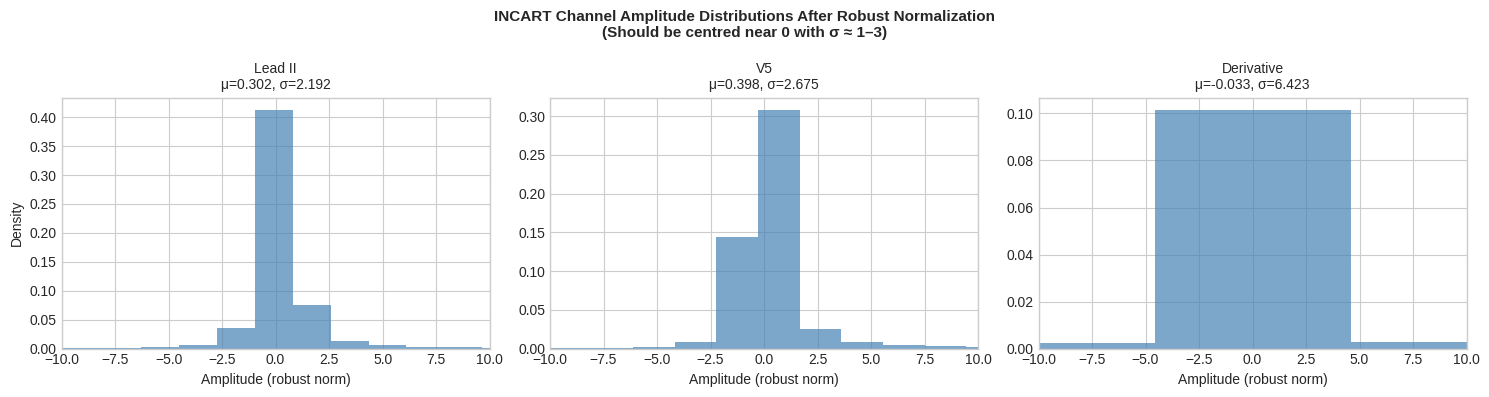

Plot 4 saved.


In [10]:
#  Plot 4: Signal amplitude statistics (verify normalization worked) 
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
channel_names = ['Lead II', 'V5', 'Derivative']

for ch, name in enumerate(channel_names):
    data = X_incart[:, ch, :].flatten()
    axes[ch].hist(data, bins=100, color='steelblue', alpha=0.7, density=True)
    axes[ch].set_title(f"{name}\nμ={data.mean():.3f}, σ={data.std():.3f}", fontsize=10)
    axes[ch].set_xlabel("Amplitude (robust norm)")
    axes[ch].set_ylabel("Density" if ch == 0 else "")
    axes[ch].set_xlim([-10, 10])

plt.suptitle("INCART Channel Amplitude Distributions After Robust Normalization\n"
             "(Should be centred near 0 with σ ≈ 1–3)", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(INCARTConfig.OUT_DIR / "incart_04_amplitude_dist.png", dpi=300, bbox_inches='tight')
plt.show()
print("Plot 4 saved.")

In [11]:
print("\n" + "=" * 60)
print("INCART PREPROCESSING COMPLETE")
print("=" * 60)
print(f"Output: {INCARTConfig.OUT_DIR.resolve()}")
print(f"Total  : {len(y_incart):,} beats from {len(INCART_RECORDS)} records")



INCART PREPROCESSING COMPLETE
Output: /kaggle/working/incart_preprocessed
Total  : 175,874 beats from 75 records
